# Coloring Lens Elements by Glass Property

By default every lens element in a layout is drawn the same color, so the glass choices behind a design are invisible. A `PropertyColorizer` maps a scalar property of each element to a color. Optiland provides two value functions for glass properties:

- `abbe_number`: the Abbe number $V_d$, computed from the indices at the d, F and C lines.
- `refractive_index(wavelength)`: the index at a given wavelength (the primary wavelength if omitted).

Elements without a value, such as mirrors or materials without dispersion data, keep the default color.

In [1]:
from optiland.samples.objectives import CookeTriplet
from optiland.samples.simple import CementedAchromat
from optiland.visualization.coloring import (
    ColorScale,
    ComponentRef,
    PropertyColorizer,
    abbe_number,
    refractive_index,
)

## Abbe number of a cemented achromat

An achromat pairs a low-dispersion crown (high $V_d$) with a high-dispersion flint (low $V_d$). Coloring by Abbe number makes the pairing visible at a glance.

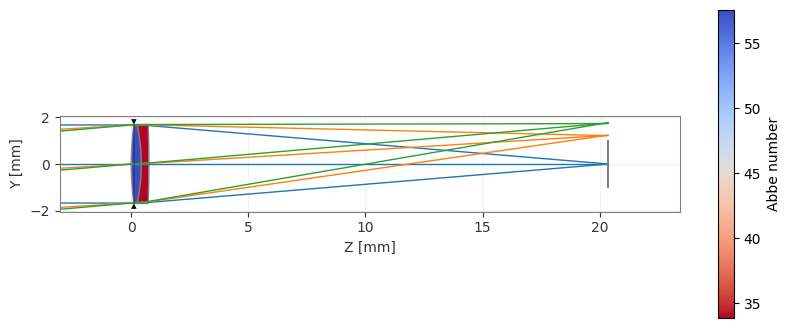

In [2]:
achromat = CementedAchromat()
fig, ax = achromat.draw(
    component_colorizer=PropertyColorizer(
        abbe_number, ColorScale(cmap="coolwarm_r", label="Abbe number")
    )
)

The value functions can also be called directly, which is a quick way to check the numbers behind the colors.

In [3]:
n_d = refractive_index(0.5876)
for ref in (ComponentRef("lens_element", (1, 2)), ComponentRef("lens_element", (2, 3))):
    glass = achromat.surfaces[ref.surface_indices[0]].material_post
    print(
        f"{glass.display_name:7s} n_d = {n_d(achromat, ref):.5f}   "
        f"V_d = {abbe_number(achromat, ref):.2f}"
    )

N-BAK1  n_d = 1.57250   V_d = 57.55
SF2     n_d = 1.64769   V_d = 33.85


## Abbe number of a Cooke triplet

The Cooke triplet places a flint negative element between two crown positive elements. Its glasses have almost the same index, so the crown-flint-crown structure only shows up in the dispersion.

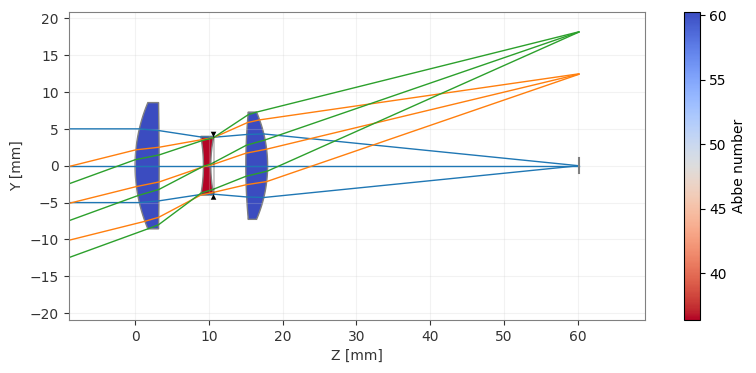

In [4]:
triplet = CookeTriplet()
fig, ax = triplet.draw(
    component_colorizer=PropertyColorizer(
        abbe_number, ColorScale(cmap="coolwarm_r", label="Abbe number")
    )
)

## Refractive index

`refractive_index` takes a wavelength in microns. Without one it uses the optic's primary wavelength, which is the d line for this achromat.

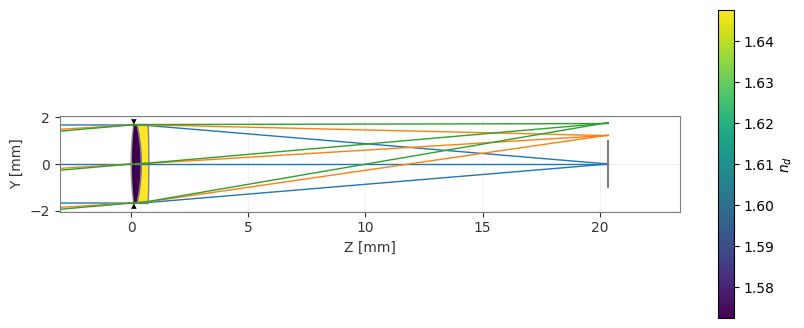

In [5]:
fig, ax = achromat.draw(
    component_colorizer=PropertyColorizer(
        refractive_index(), ColorScale(label="$n_d$")
    )
)